# Enterprise Data Cleaning & Quality Audit
### Olist E-Commerce | Beginner Data Analyst Project
**Tools:** Python, pandas, NumPy, Matplotlib. Run cells in order. No SQL or advanced Python.

## 1. Load the raw data
The notebook is in `notebooks`. Raw CSVs are in `../data_raw`. Your original CSVs will not be changed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
customers = pd.read_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_raw\olist_customers_dataset.csv")
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
orders = pd.read_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_raw\olist_orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:
items = pd.read_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_raw\olist_order_items_dataset.csv")
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [9]:
payments = pd.read_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_raw\olist_order_payments_dataset.csv")
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [11]:
reviews = pd.read_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_raw\olist_order_reviews_dataset.csv")
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [13]:
products = pd.read_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_raw\olist_products_dataset.csv")
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [15]:
sellers = pd.read_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_raw\olist_sellers_dataset.csv")
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [17]:
geo = pd.read_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_raw\olist_geolocation_dataset.csv")
geo.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [19]:
categories = pd.read_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_raw\product_category_name_translation.csv")
categories.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


## 2. Understand the data
Look at table sizes, column names, missing values and duplicate rows before cleaning.

In [22]:
data = {"customers": customers, "orders": orders, "items": items, "payments": payments, "reviews": reviews, "products": products, "sellers": sellers, "geolocation": geo, "categories": categories}
print("Number of datasets:", len(data))

Number of datasets: 9


In [24]:
for name, table in data.items():
    print(name, "-", table.shape[0], "rows and", table.shape[1], "columns")

customers - 99441 rows and 5 columns
orders - 99441 rows and 8 columns
items - 112650 rows and 7 columns
payments - 103886 rows and 5 columns
reviews - 99224 rows and 7 columns
products - 32951 rows and 9 columns
sellers - 3095 rows and 4 columns
geolocation - 1000163 rows and 5 columns
categories - 71 rows and 2 columns


In [26]:
print(orders.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
None


In [28]:
print(items.describe())

       order_item_id          price  freight_value
count  112650.000000  112650.000000  112650.000000
mean        1.197834     120.653739      19.990320
std         0.705124     183.633928      15.806405
min         1.000000       0.850000       0.000000
25%         1.000000      39.900000      13.080000
50%         1.000000      74.990000      16.260000
75%         1.000000     134.900000      21.150000
max        21.000000    6735.000000     409.680000


## 3. Find missing values
Missing values are not always errors. For example, a review comment is optional.

In [31]:
print(orders.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [33]:
print(reviews.isnull().sum())

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


In [35]:
missing_before = {}
for name, table in data.items():
    missing_before[name] = table.isnull().sum().sum()
print(pd.Series(missing_before))

customers           0
orders           4908
items               0
payments            0
reviews        145903
products         2448
sellers             0
geolocation         0
categories          0
dtype: int64


## 4. Find duplicates
We count only **completely identical rows**, not repeated order IDs. One order may have multiple products or payments.

In [38]:
duplicates_before = {}
for name, table in data.items():
    duplicates_before[name] = table.duplicated().sum()
print(pd.Series(duplicates_before))

customers           0
orders              0
items               0
payments            0
reviews             0
products            0
sellers             0
geolocation    261831
categories          0
dtype: int64


In [39]:
print("Duplicate customer rows:", customers.duplicated().sum())
print("Duplicate geolocation rows:", geo.duplicated().sum())

Duplicate customer rows: 0
Duplicate geolocation rows: 261831


## 5. Clean the data
Make copies and remove only exact duplicate rows. Keep valid missing values rather than filling them with made-up information.

In [42]:
clean = {}
for name, table in data.items():
    clean[name] = table.copy()
print("Copies created")

Copies created


In [45]:
for name in clean:
    clean[name] = clean[name].drop_duplicates()
print("Exact duplicates removed")

Exact duplicates removed


In [46]:
print("Raw geolocation rows:", len(geo))
print("Clean geolocation rows:", len(clean["geolocation"]))

Raw geolocation rows: 1000163
Clean geolocation rows: 738332


## 6. Simple data validation
Flag unusual data for review instead of deleting it automatically.

In [50]:
bad_prices = clean["items"][(clean["items"]["price"] <= 0) | (clean["items"]["freight_value"] < 0)]
print("Invalid price or freight rows:", len(bad_prices))

Invalid price or freight rows: 0


In [52]:
bad_payments = clean["payments"][clean["payments"]["payment_value"] < 0]
print("Negative payment rows:", len(bad_payments))

Negative payment rows: 0


In [54]:
bad_scores = clean["reviews"][(clean["reviews"]["review_score"] < 1) | (clean["reviews"]["review_score"] > 5)]
print("Invalid review scores:", len(bad_scores))

Invalid review scores: 0


In [56]:
bad_geo = clean["geolocation"][(clean["geolocation"]["geolocation_lat"] < -90) | (clean["geolocation"]["geolocation_lat"] > 90) | (clean["geolocation"]["geolocation_lng"] < -180) | (clean["geolocation"]["geolocation_lng"] > 180)]
print("Invalid global coordinates:", len(bad_geo))

Invalid global coordinates: 0


## 7. Check table relationships
`isin()` checks whether IDs appear in the related table. We flag missing links, but do not delete records without investigation.

In [59]:
unknown_customers = clean["orders"][~clean["orders"]["customer_id"].isin(clean["customers"]["customer_id"])]
print("Orders with unknown customers:", len(unknown_customers))

Orders with unknown customers: 0


In [61]:
unknown_orders = clean["items"][~clean["items"]["order_id"].isin(clean["orders"]["order_id"])]
print("Items with unknown orders:", len(unknown_orders))

Items with unknown orders: 0


In [63]:
unknown_products = clean["items"][~clean["items"]["product_id"].isin(clean["products"]["product_id"])]
print("Items with unknown products:", len(unknown_products))

Items with unknown products: 0


In [65]:
unknown_sellers = clean["items"][~clean["items"]["seller_id"].isin(clean["sellers"]["seller_id"])]
print("Items with unknown sellers:", len(unknown_sellers))

Items with unknown sellers: 0


In [67]:
unknown_payments = clean["payments"][~clean["payments"]["order_id"].isin(clean["orders"]["order_id"])]
print("Payments with unknown orders:", len(unknown_payments))

Payments with unknown orders: 0


## 8. Create an exceptions report
This report shows the number of rows that need further review.

In [70]:
exceptions = pd.DataFrame({"check": ["Invalid item price/freight", "Negative payments", "Invalid review scores", "Invalid coordinates", "Unknown customer", "Unknown item order", "Unknown product", "Unknown seller", "Unknown payment order"], "rows_found": [len(bad_prices), len(bad_payments), len(bad_scores), len(bad_geo), len(unknown_customers), len(unknown_orders), len(unknown_products), len(unknown_sellers), len(unknown_payments)]})
exceptions

,check,rows_found
0,Invalid item price/freight,0
1,Negative payments,0
2,Invalid review scores,0
3,Invalid coordinates,0
4,Unknown customer,0
5,Unknown item order,0
6,Unknown product,0
7,Unknown seller,0
8,Unknown payment order,0


## 9. Compare before and after cleaning
Removing duplicate rows does not necessarily reduce missing values. Both results are reported honestly.

In [73]:
comparison = pd.DataFrame({"dataset": list(data.keys()), "rows_before": [len(data[name]) for name in data], "rows_after": [len(clean[name]) for name in data], "duplicates_before": [duplicates_before[name] for name in data], "missing_before": [missing_before[name] for name in data], "missing_after": [clean[name].isnull().sum().sum() for name in data]})
comparison

,dataset,rows_before,rows_after,duplicates_before,missing_before,missing_after
0,customers,99441,99441,0,0,0
1,orders,99441,99441,0,4908,4908
2,items,112650,112650,0,0,0
3,payments,103886,103886,0,0,0
4,reviews,99224,99224,0,145903,145903
5,products,32951,32951,0,2448,2448
6,sellers,3095,3095,0,0,0
7,geolocation,1000163,738332,261831,0,0
8,categories,71,71,0,0,0


In [75]:
print("Total original rows:", comparison["rows_before"].sum())
print("Total cleaned rows:", comparison["rows_after"].sum())
print("Exact duplicate rows removed:", (comparison["rows_before"] - comparison["rows_after"]).sum())

Total original rows: 1550922
Total cleaned rows: 1289091
Exact duplicate rows removed: 261831


## 10. Visualize data quality
Use simple Matplotlib bar charts.

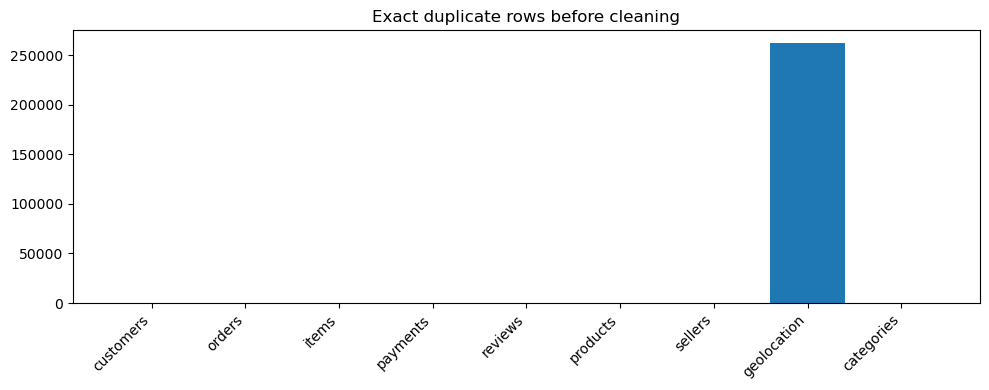

In [78]:
plt.figure(figsize=(10, 4))
plt.bar(comparison["dataset"], comparison["duplicates_before"])
plt.xticks(rotation=45, ha="right")
plt.title("Exact duplicate rows before cleaning")
plt.tight_layout()
plt.savefig("../reports/duplicates_before.png")
plt.show()

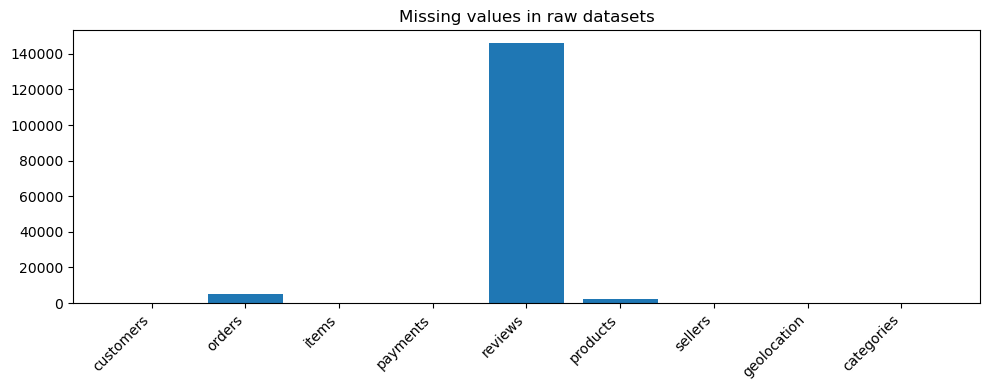

In [79]:
plt.figure(figsize=(10, 4))
plt.bar(comparison["dataset"], comparison["missing_before"])
plt.xticks(rotation=45, ha="right")
plt.title("Missing values in raw datasets")
plt.tight_layout()
plt.savefig("../reports/missing_values.png")
plt.show()

## 11. Basic business KPIs
These are simple counts to understand the dataset.

In [83]:
print("Orders:", len(clean["orders"]))
print("Unique customers:", clean["customers"]["customer_unique_id"].nunique())
print("Products:", len(clean["products"]))
print("Sellers:", len(clean["sellers"]))

Orders: 99441
Unique customers: 96096
Products: 32951
Sellers: 3095


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


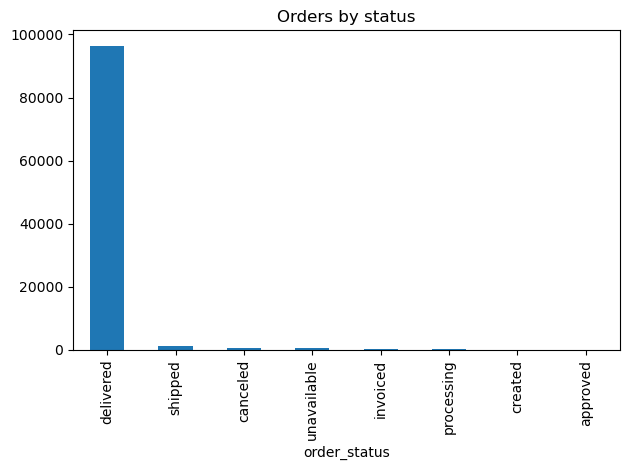

In [85]:
status = clean["orders"]["order_status"].value_counts()
print(status)
status.plot(kind="bar", title="Orders by status")
plt.tight_layout()
plt.savefig("../reports/order_status.png")
plt.show()

## 12. Save the cleaned datasets and reports
The notebook writes CSVs to `data_cleaned` and reports/graphs to `reports`. Your original files stay unchanged.

In [102]:
import os

# Folder where cleaned files will be saved
folder = r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\data_cleaned"

# Save all cleaned datasets
for name, table in clean.items():
    table.to_csv(os.path.join(folder, name + "_cleaned.csv"), index=False)

print("Saved all 9 cleaned CSV files")


Saved all 9 cleaned CSV files


In [104]:
exceptions.to_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\reports\exceptions_summary.csv", index=False)
comparison.to_csv(r"C:\Users\gadeb\OneDrive\Desktop\Ecommerce_Business_Analytics\reports\quality_comparison.csv", index=False)
print("Saved both audit reports")

Saved both audit reports


## 13. Conclusion
- Explored nine Olist datasets using pandas.
- Counted missing values and exact duplicates.
- Removed only fully identical rows from copies of the data.
- Checked prices, payments, review scores, coordinates and linked IDs.
- Saved nine cleaned datasets, two audit tables and three graphs.

**Note:** Some missing values are legitimate. Exceptions need business review before correction. This is a basic quality audit, not a guarantee that all data errors have been fixed.

In [107]:
print("PROJECT COMPLETE")
print("Total exceptions flagged:", exceptions["rows_found"].sum())
print("Review the reports folder for results.")

PROJECT COMPLETE
Total exceptions flagged: 0
Review the reports folder for results.
